# Final Project: ยอดขายวิดีโอเกมทั่วโลก

> 1145 201 คณิตศาสตร์สำหรับวิทยาการข้อมูล | Semester 1/2568

**กลุ่ม:**
- สมาชิกที่ 1: นายอัครพนธ์ โอมาโฮนี่ (68114540719)
- สมาชิกที่ 2: นายรักชนก ไชยรินทร์ (68114540496)

**Dataset:** Video Game Sales โดย Gregory Smith (scrape จาก vgchartz.com) — [Kaggle](https://www.kaggle.com/datasets/gregorut/videogamesales) · [Zenodo](https://doi.org/10.5281/zenodo.5898311) (license CC BY 4.0)  
มี 16,598 เกม 11 คอลัมน์ ยอดขายมีหน่วยเป็นล้านชุดและปัดเป็นทศนิยมสองตำแหน่ง

**Problem Statement:** ชุดข้อมูลนี้มียอดขายเกมแยกตามภูมิภาค พร้อมปีที่วางจำหน่าย ประเภทเกม แพลตฟอร์ม และผู้จัดจำหน่าย โครงงานนี้ศึกษาว่าปัจจัยเหล่านี้สัมพันธ์กับยอดขายทั่วโลกอย่างไร แล้วสร้างโมเดล Regression เพื่อทำนายยอดขาย ประเด็นนี้น่าสนใจเพราะช่วยให้เห็นว่าเกมลักษณะไหนมักขายได้มากกว่า และประเมินได้ว่าข้อมูลที่รู้ก่อนเกมวางขายทำนายยอดขายได้ดีแค่ไหน ยอดขายรายภูมิภาคไม่ถูกใช้เป็นตัวแปรต้น เพราะผลรวมของสี่ภูมิภาคเกือบเท่ากับ Global Sales

---

| CLO | ส่วนที่ครอบคลุม | Status |
|-----|----------------|--------|
| CLO1 (Linear Algebra) | Part 2 | ✅ |
| CLO2 (Statistical Learning) | Part 3 | ✅ |
| CLO3 (Regression/Classification) | Part 4 | ✅ |
| CLO4 (Model Selection) | Part 5 | ✅ |

In [1]:
# ─── Import libraries ───
# วัตถุประสงค์: เตรียมเครื่องมือสำหรับพีชคณิตเชิงเส้น สถิติ และ regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, cross_val_predict, cross_validate,
)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA

np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")
print("Ready.")

Ready.


---
## Part 1: Dataset Overview และ EDA เบื้องต้น

ในส่วนนี้ให้โหลด dataset, แสดง basic statistics, และทำ EDA เบื้องต้นเพื่อเข้าใจข้อมูลก่อนวิเคราะห์

**สิ่งที่ต้องทำ:**
- โหลด dataset และแสดง shape, dtypes, missing values
- แสดง descriptive statistics ด้วย `.describe()`
- Plot distribution ของ target variable
- Plot correlation heatmap หรือ scatter matrix

In [2]:
# ─── โหลดข้อมูล ───
# วัตถุประสงค์: ดูขนาด ชนิดข้อมูล และค่าที่หายไป
DATA_URL = "https://raw.githubusercontent.com/akkraraphonom/final-vgsales-68114540719/main/vgsales.csv"
try:
    df = pd.read_csv("vgsales.csv")
except FileNotFoundError:
    df = pd.read_csv(DATA_URL)

print("ขนาดข้อมูล:", df.shape)
print("\nชนิดข้อมูล:")
print(df.dtypes)
print("\nค่าว่างในแต่ละคอลัมน์:")
print(df.isnull().sum())
display(df.head())

ขนาดข้อมูล: (16598, 11)

ชนิดข้อมูล:
Rank              int64
Name                str
Platform            str
Year            float64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

ค่าว่างในแต่ละคอลัมน์:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


,count,mean,std,min,25%,50%,75%,max
Rank,16598.0,8300.605254,4791.853933,1.00,4151.25,8300.50,12449.75,16600.00
Year,16327.0,2006.406443,5.828981,1980.00,2003.00,2007.00,2010.00,2020.00
NA_Sales,16598.0,0.264667,0.816683,0.00,0.00,0.08,0.24,41.49
EU_Sales,16598.0,0.146652,0.505351,0.00,0.00,0.02,0.11,29.02
JP_Sales,16598.0,0.077782,0.309291,0.00,0.00,0.00,0.04,10.22
Other_Sales,16598.0,0.048063,0.188588,0.00,0.00,0.01,0.04,10.57
Global_Sales,16598.0,0.537441,1.555028,0.01,0.06,0.17,0.47,82.74


สัดส่วนเกมที่ขายได้ไม่ถึง 0.2 ล้านชุด: 53.4%
ยอดขายต่ำสุด = 0.01 ล้านชุด | สัดส่วนเกมที่ขายได้ไม่ถึง 0.1 ล้านชุด: 34.8%


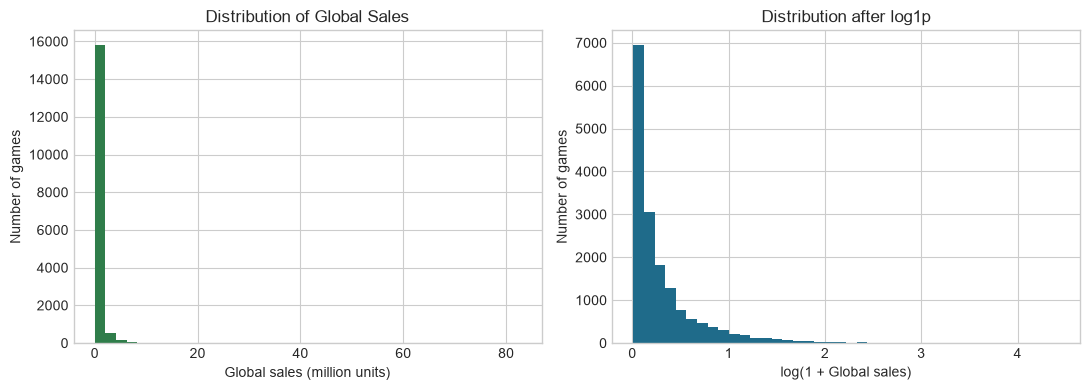

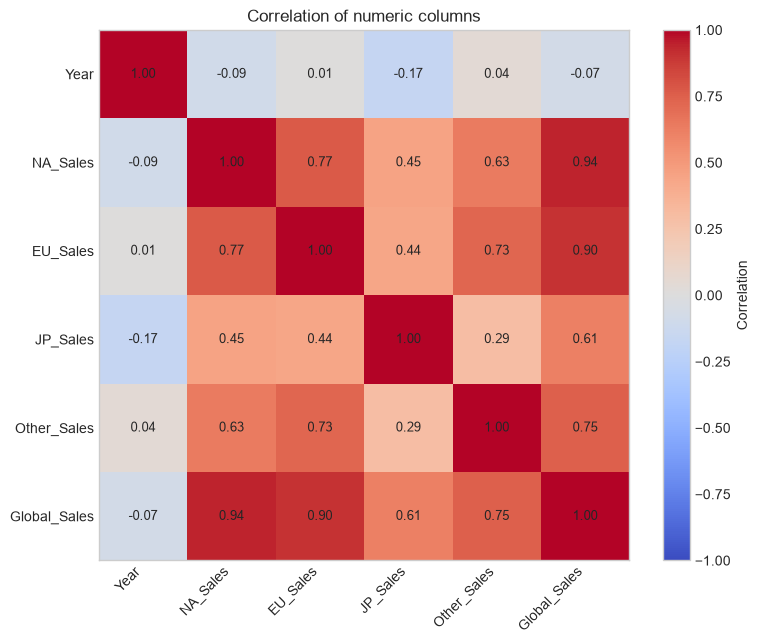

ผลรวม 4 ภูมิภาคต่างจาก Global_Sales มากที่สุด 0.02 ล้านชุด


In [3]:
# ─── สถิติเบื้องต้นและการกระจายของเป้าหมาย ───
# วัตถุประสงค์: ดูว่า Global_Sales เบ้หรือไม่ และคอลัมน์ตัวเลขใดสัมพันธ์กัน
display(df.describe().T)
print("สัดส่วนเกมที่ขายได้ไม่ถึง 0.2 ล้านชุด: {:.1%}".format((df["Global_Sales"] < 0.2).mean()))
print("ยอดขายต่ำสุด = {:.2f} ล้านชุด | สัดส่วนเกมที่ขายได้ไม่ถึง 0.1 ล้านชุด: {:.1%}".format(
    df["Global_Sales"].min(), (df["Global_Sales"] < 0.1).mean()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["Global_Sales"], bins=40, color="#2f7d4a")
axes[0].set_xlabel("Global sales (million units)")
axes[0].set_ylabel("Number of games")
axes[0].set_title("Distribution of Global Sales")

axes[1].hist(np.log1p(df["Global_Sales"]), bins=40, color="#1f6b8a")
axes[1].set_xlabel("log(1 + Global sales)")
axes[1].set_ylabel("Number of games")
axes[1].set_title("Distribution after log1p")
plt.tight_layout()
plt.show()

region_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
numeric_df = df.select_dtypes(include="number").drop(columns=["Rank"])
corr = numeric_df.corr()

plt.figure(figsize=(8, 6.5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.grid(False)
plt.colorbar(label="Correlation")
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, "{:.2f}".format(corr.iloc[i, j]), ha="center", va="center", fontsize=9)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation of numeric columns")
plt.tight_layout()
plt.show()

region_gap = (df["Global_Sales"] - df[region_cols].sum(axis=1)).abs()
print("ผลรวม 4 ภูมิภาคต่างจาก Global_Sales มากที่สุด {:.2f} ล้านชุด".format(region_gap.max()))

ยอดขายดิบเบ้ขวามาก เกมประมาณ 53% ขายได้ไม่ถึง 0.2 ล้านชุด แต่บางเกมขายได้หลายสิบล้านชุด เกมที่ขายสูงสุดคือ Wii Sports ที่ 82.74 ล้านชุด กราฟหลัง `log1p` อ่านการกระจายได้ง่ายกว่า จึงใช้ `log(1 + Global_Sales)` เป็นตัวแปรตามของโมเดล

คำอธิบายของชุดข้อมูลบน Kaggle และ Zenodo บอกว่าเป็นเกมที่ขายได้เกิน 100,000 ชุด แต่ในไฟล์จริงยอดขายต่ำสุดคือ 0.01 ล้านชุด (10,000 ชุด) และเกม 34.8% ขายได้ไม่ถึง 0.1 ล้านชุด รายงานนี้จึงไม่ใช้เงื่อนไขนั้นในการตีความ

ใน heatmap ยอดขายอเมริกาเหนือ (r = 0.94) ยุโรป (0.90) ภูมิภาคอื่น (Other_Sales, 0.75) และญี่ปุ่น (0.61) สัมพันธ์กับ Global Sales สูง เพราะเป็นส่วนประกอบของยอดขายโลก ผลรวมสี่ภูมิภาคต่างจาก Global Sales ไม่เกิน 0.02 ล้านชุดซึ่งมาจากการปัดเศษ ส่วนปีที่วางจำหน่ายแทบไม่สัมพันธ์กับยอดขาย (r = −0.07) คอลัมน์ Rank ไม่ถูกใช้ เพราะอันดับถูกจัดจากยอดขายอยู่แล้ว

---
## Part 2: CLO1 — Linear Algebra Analysis

ในส่วนนี้ให้ใช้ Linear Algebra เพื่อ analyze dataset

**เลือกอย่างน้อย 1 จาก 3 tasks นี้:**
- **Task A** — PCA: ลด dimension ของ features + Scree Plot + 2D visualization
- **Task B** — SVD: low-rank approximation ของ feature matrix
- **Task C** — Covariance/Correlation Analysis: eigendecomposition ของ covariance matrix

**คำอธิบาย:** เลือก Task C ร่วมกับ Task A ข้อแรกคำนวณ covariance matrix ของยอดขายสี่ภูมิภาค เพื่อดูว่าตลาดใดแปรผันไปด้วยกัน ข้อสองทำ eigendecomposition ของ covariance matrix ของตัวแปรต้น (Year และ dummy ของ Genre, Platform, Publisher) แล้วใช้ PCA ดูว่าข้อมูลหลายสิบมิตินี้ยุบเหลือไม่กี่แกนได้หรือไม่ คาดว่าตลาดตะวันตกจะเคลื่อนไปด้วยกัน และ dummy จำนวนมากจะทำให้ variance กระจายไปหลาย component

In [4]:
# ─── เตรียมตารางวิเคราะห์ ───
# วัตถุประสงค์: ตัดแถวที่ปีหรือผู้จัดจำหน่ายหาย จัดผู้จัดจำหน่ายนอก 15 อันดับแรกเป็น Other และสร้าง dummy variables
work = df.dropna(subset=["Year", "Publisher", "Global_Sales"]).copy()
work["Year"] = work["Year"].astype(int)
work["log_sales"] = np.log1p(work["Global_Sales"])

top_publishers = work["Publisher"].value_counts().head(15).index
work["Publisher_group"] = np.where(
    work["Publisher"].isin(top_publishers), work["Publisher"], "Other"
)

features = ["Year", "Genre", "Platform", "Publisher_group"]
X_df = pd.get_dummies(work[features], drop_first=True, dtype=float)
y = work["log_sales"].to_numpy()

print("จำนวนเกมที่ใช้วิเคราะห์:", len(work))
print("ตัดแถวที่ Year หรือ Publisher หายไป:", len(df) - len(work),
      "| หายทั้งสองค่า:", int((df["Year"].isna() & df["Publisher"].isna()).sum()))
print(
    "จำนวนหมวด: Genre =", work["Genre"].nunique(),
    "| Platform =", work["Platform"].nunique(),
    "| Publisher_group =", work["Publisher_group"].nunique(),
)
print("จำนวน features หลังทำ dummy:", X_df.shape[1])
print(
    "หมวดอ้างอิงที่ drop_first ตัดออก: Genre =", sorted(work["Genre"].unique())[0],
    "| Platform =", sorted(work["Platform"].unique())[0],
    "| Publisher =", sorted(work["Publisher_group"].unique())[0],
)

จำนวนเกมที่ใช้วิเคราะห์: 16291
ตัดแถวที่ Year หรือ Publisher หายไป: 307 | หายทั้งสองค่า: 22
จำนวนหมวด: Genre = 12 | Platform = 31 | Publisher_group = 16
จำนวน features หลังทำ dummy: 57
หมวดอ้างอิงที่ drop_first ตัดออก: Genre = Action | Platform = 2600 | Publisher = Activision


In [5]:
# ─── Covariance matrix ของยอดขายรายภูมิภาค ───
# วัตถุประสงค์: คำนวณ Σ = XᵀX / (n − 1) จากข้อมูลที่ลบค่าเฉลี่ยแล้ว แปลงเป็น correlation และหา eigenvalues
region = work[region_cols].to_numpy()
centered = region - region.mean(axis=0)
sigma_region = centered.T @ centered / (len(region) - 1)
print("Covariance matrix Σ (หน่วย: ล้านชุด²)")
display(pd.DataFrame(sigma_region, index=region_cols, columns=region_cols).round(4))
print("ตรงกับ np.cov:", np.allclose(sigma_region, np.cov(region, rowvar=False)))

region_sd = np.sqrt(np.diag(sigma_region))
corr_region = sigma_region / np.outer(region_sd, region_sd)
print("\nCorrelation matrix = Σᵢⱼ / (σᵢσⱼ)")
display(pd.DataFrame(corr_region, index=region_cols, columns=region_cols).round(3))

eig_region = np.sort(np.linalg.eigvalsh(corr_region))[::-1]
print("Eigenvalues ของ correlation matrix:", np.round(eig_region, 3))
print("สัดส่วน variance:", np.round(eig_region / eig_region.sum(), 3))

Covariance matrix Σ (หน่วย: ล้านชุด²)


,NA_Sales,EU_Sales,JP_Sales,Other_Sales
NA_Sales,0.6764,0.3221,0.1158,0.0992
EU_Sales,0.3221,0.2594,0.0693,0.0703
JP_Sales,0.1158,0.0693,0.0973,0.0172
Other_Sales,0.0992,0.0703,0.0172,0.0361


ตรงกับ np.cov: True

Correlation matrix = Σᵢⱼ / (σᵢσⱼ)


,NA_Sales,EU_Sales,JP_Sales,Other_Sales
NA_Sales,1.000,0.769,0.451,0.635
EU_Sales,0.769,1.000,0.436,0.726
JP_Sales,0.451,0.436,1.000,0.291
Other_Sales,0.635,0.726,0.291,1.000


Eigenvalues ของ correlation matrix: [2.697 0.754 0.34  0.209]
สัดส่วน variance: [0.674 0.189 0.085 0.052]


ขนาดของ Σ: (57, 57)
ผลรวม eigenvalues = trace(Σ) = 57.003
PC1 อธิบาย variance ได้ 3.7% | PC1+PC2 = 6.7%
จำนวน components ที่สะสมถึง 80%: 40
จำนวน components ที่สะสมถึง 90%: 46

Eigenvalues ของ PC1–PC10 และ PC ที่สะสมถึง 80% กับ 90%


,Eigenvalue (λ),Variance explained (%),Cumulative (%)
PC,,,
PC1,2.090,3.667,3.667
PC2,1.746,3.063,6.731
PC3,1.608,2.821,9.552
PC4,1.518,2.663,12.215
PC5,1.398,2.452,14.667
PC6,1.375,2.412,17.079
PC7,1.346,2.362,19.441
PC8,1.293,2.268,21.709
PC9,1.238,2.171,23.880



คู่ features ที่ |covariance| สูงสุด (หลัง standardize ค่านี้ใกล้เคียง correlation)


,feature_1,feature_2,covariance
0,Year,Platform_PS,-0.404
1,Year,Platform_SNES,-0.263
2,Year,Platform_NES,-0.257
3,Publisher_group_Electronic Arts,Publisher_group_Other,-0.249
4,Genre_Sports,Publisher_group_Electronic Arts,0.234
5,Year,Platform_PS3,0.223
6,Platform_GB,Publisher_group_Nintendo,0.220
7,Platform_SAT,Publisher_group_Sega,0.218


ตรวจกับ sklearn PCA: [0.0367 0.0306] | λ/Σλ: [0.0367 0.0306]
r(PC1 score, log sales) = -0.157 | r(PC2 score, log sales) = 0.137

Loading ที่ค่าสัมบูรณ์สูงสุดบน PC1:


,PC1 loading
Year,0.633
Platform_PS,-0.291
Platform_NES,-0.186
Platform_SNES,-0.169
Platform_PSV,0.164
Genre_Platform,-0.158


Loading ที่ค่าสัมบูรณ์สูงสุดบน PC2:


,PC2 loading
Genre_Sports,0.395
Publisher_group_Other,-0.393
Publisher_group_Electronic Arts,0.385
Platform_DS,-0.293
Genre_Puzzle,-0.240
Publisher_group_Nintendo,-0.214


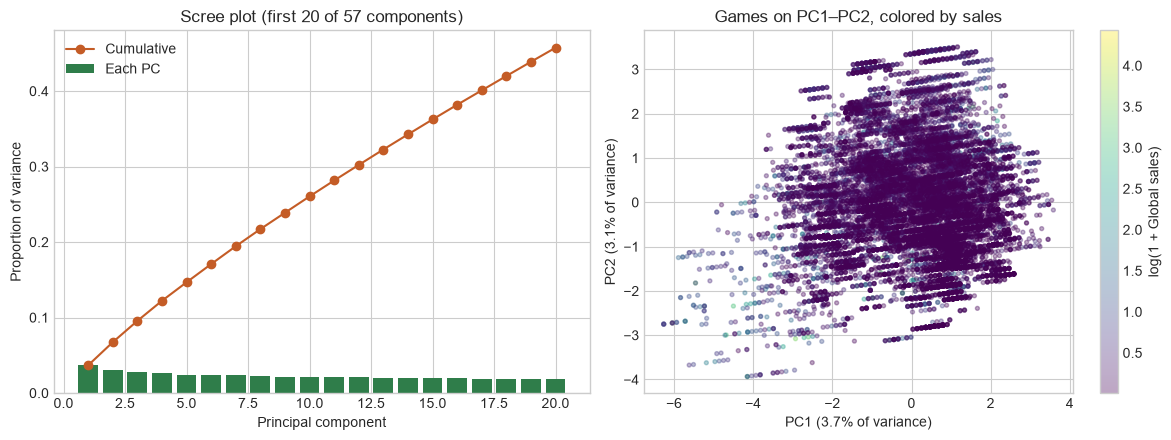

In [6]:
# ─── PCA ของตัวแปรที่ใช้ทำนาย ───
# วัตถุประสงค์: eigendecomposition ของ covariance matrix ของ features ที่ standardize แล้ว พร้อม scree plot และภาพ PC1–PC2
X_scaled = StandardScaler().fit_transform(X_df)
sigma = np.cov(X_scaled, rowvar=False)
eigvals = np.sort(np.linalg.eigvalsh(sigma))[::-1]
variance_ratio = eigvals / eigvals.sum()
cumulative = np.cumsum(variance_ratio)

n_80 = int(np.searchsorted(cumulative, 0.80) + 1)
n_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print("ขนาดของ Σ:", sigma.shape)
print("ผลรวม eigenvalues = trace(Σ) = {:.3f}".format(eigvals.sum()))
print("PC1 อธิบาย variance ได้ {:.1%} | PC1+PC2 = {:.1%}".format(variance_ratio[0], variance_ratio[:2].sum()))
print("จำนวน components ที่สะสมถึง 80%:", n_80)
print("จำนวน components ที่สะสมถึง 90%:", n_90)

eig_table = pd.DataFrame(
    {
        "Eigenvalue (λ)": eigvals,
        "Variance explained (%)": variance_ratio * 100,
        "Cumulative (%)": cumulative * 100,
    },
    index=pd.Index(["PC{}".format(k) for k in range(1, len(eigvals) + 1)], name="PC"),
)
print("\nEigenvalues ของ PC1–PC10 และ PC ที่สะสมถึง 80% กับ 90%")
display(eig_table.iloc[list(range(10)) + [n_80 - 1, n_90 - 1]].round(3))

names = list(X_df.columns)
pair_rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        pair_rows.append({"feature_1": names[i], "feature_2": names[j], "covariance": sigma[i, j]})
pairs = pd.DataFrame(pair_rows)
pairs = pairs.reindex(pairs["covariance"].abs().sort_values(ascending=False).index)
print("\nคู่ features ที่ |covariance| สูงสุด (หลัง standardize ค่านี้ใกล้เคียง correlation)")
display(pairs.head(8).round(3).reset_index(drop=True))

pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)
print("ตรวจกับ sklearn PCA:", np.round(pca.explained_variance_ratio_, 4), "| λ/Σλ:", np.round(variance_ratio[:2], 4))

# เครื่องหมายของ eigenvector กลับได้โดยไม่เปลี่ยนความหมาย จึงกำหนดให้ loading ที่ |ค่า| มากสุดของแต่ละ PC เป็นบวก
components = pca.components_
signs = np.sign(components[np.arange(2), np.abs(components).argmax(axis=1)])
components = components * signs[:, None]
scores = scores * signs
print("r(PC1 score, log sales) = {:.3f} | r(PC2 score, log sales) = {:.3f}".format(
    np.corrcoef(scores[:, 0], work["log_sales"])[0, 1], np.corrcoef(scores[:, 1], work["log_sales"])[0, 1]))

load_pc1 = pd.Series(components[0], index=X_df.columns)
load_pc2 = pd.Series(components[1], index=X_df.columns)
print("\nLoading ที่ค่าสัมบูรณ์สูงสุดบน PC1:")
display(load_pc1.reindex(load_pc1.abs().sort_values(ascending=False).head(6).index).round(3).to_frame("PC1 loading"))
print("Loading ที่ค่าสัมบูรณ์สูงสุดบน PC2:")
display(load_pc2.reindex(load_pc2.abs().sort_values(ascending=False).head(6).index).round(3).to_frame("PC2 loading"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
show_k = 20
axes[0].bar(range(1, show_k + 1), variance_ratio[:show_k], color="#2f7d4a", label="Each PC")
axes[0].plot(range(1, show_k + 1), cumulative[:show_k], color="#c45c26", marker="o", label="Cumulative")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Proportion of variance")
axes[0].set_title("Scree plot (first 20 of 57 components)")
axes[0].legend()

sc = axes[1].scatter(scores[:, 0], scores[:, 1], c=work["log_sales"], cmap="viridis", s=8, alpha=0.35)
plt.colorbar(sc, ax=axes[1], label="log(1 + Global sales)")
axes[1].set_xlabel("PC1 ({:.1%} of variance)".format(variance_ratio[0]))
axes[1].set_ylabel("PC2 ({:.1%} of variance)".format(variance_ratio[1]))
axes[1].set_title("Games on PC1–PC2, colored by sales")
plt.tight_layout()
plt.show()

**Insight จาก CLO1 Analysis:**

- **Covariance ของยอดขายภูมิภาค:** อเมริกาเหนือมี variance สูงสุด (0.676 ล้านชุด²) และคู่ที่ covariance สูงสุดคืออเมริกาเหนือกับยุโรป (0.322) หลังหารด้วยส่วนเบี่ยงเบนมาตรฐานจะได้ correlation 0.77 ส่วนญี่ปุ่นสัมพันธ์กับอีกสามภูมิภาคต่ำกว่า (0.29–0.45) และคู่ที่ต่ำสุดคือญี่ปุ่นกับ Other_Sales (covariance 0.017, correlation 0.29) eigenvalue แรกของ correlation matrix (λ1 = 2.70 จาก 4) อธิบาย variance ได้ประมาณ 67% แปลว่าเกมที่ขายดีในตลาดหนึ่งมักขายดีในตลาดอื่นด้วย แต่ตลาดญี่ปุ่นมีรูปแบบของตัวเองมากกว่า
- **Covariance ของตัวแปรต้น:** คู่ที่ covariance เด่นที่สุดคือ Year กับแพลตฟอร์มยุคเก่า เช่น PS (−0.40), SNES (−0.26), NES (−0.26) ซึ่งเป็นลบเพราะเครื่องเหล่านี้มีเกมเฉพาะช่วงปีแรก ๆ ส่วนคู่บวกที่สมเหตุสมผลคือ Sports กับ Electronic Arts (0.23), GB กับ Nintendo (0.22) และ Saturn กับ Sega (0.22) เพราะเป็นผู้ผลิตเครื่องหรือค่ายที่ทำเกมแนวนั้นเป็นหลัก
- **Eigenvalues และ PCA:** covariance matrix ของตัวแปรต้นมีขนาด 57 × 57 ผลรวม eigenvalues เท่ากับ trace ประมาณ 57 λ1 = 2.09 จึงอธิบาย variance ได้เพียง 3.7% PC1 กับ PC2 รวมกันได้ 6.7% eigenvalue ลดลงช้ามาก (λ10 ยังเท่ากับ 1.23) และต้องใช้ 40 components จึงถึง 80% และ 46 components จึงถึง 90% เพราะ dummy แต่ละตัวแทบไม่ซ้ำข้อมูลกัน กราฟสองมิติจึงเป็นภาพคร่าว ๆ ไม่ใช่การย่อข้อมูลทั้งหมด
- **ความหมายของแกน:** PC1 แยกเกมที่ออกปีหลัง ๆ (Year สูง และ PS Vita) ออกจากเกมบนแพลตฟอร์มยุคเก่า (PS, NES, SNES) จึงเป็นแกน “ยุคของเกม” ส่วน PC2 แยกเกมกีฬาของ Electronic Arts ออกจากเกมบน DS เกม Puzzle เกมของ Nintendo และค่ายเล็กในกลุ่ม Other ในกราฟ จุดสีอ่อนซึ่งยอดขายสูงพบมากกว่าทางฝั่งเกมยุคเก่าของ PC1 (r ระหว่างคะแนน PC1 กับ log sales = −0.16 ส่วน PC2 = 0.14) สอดคล้องกับ t-test ใน Part 3 แต่โดยรวมสีของจุดยังปนกันมาก ไม่แยกเป็นกลุ่มตามยอดขาย แปลว่ายอดขายไม่ได้ถูกกำหนดด้วยแกนหลักของตัวแปรต้นเพียงแกนเดียว

---
## Part 3: CLO2 — Statistical Learning

ในส่วนนี้ให้ทำ Statistical Analysis ที่เกี่ยวข้องกับ dataset

**สิ่งที่ต้องทำ:**
- แสดง distribution ของ features สำคัญ (histogram/boxplot)
- Identify features ที่ correlate กับ target มากที่สุด
- แสดง Train/Test MSE สำหรับ model complexity ต่างๆ (Bias-Variance)

**คำถาม:** dataset ของคุณเหมาะกับ Regression หรือ Classification? เพราะอะไร?

**คำตอบ:** เหมาะกับ **Regression** เพราะ Global Sales เป็นจำนวนชุดที่ขายได้ ซึ่งเป็นตัวเลขต่อเนื่อง ถ้าตัดยอดขายเป็นกลุ่ม เช่น ขายดีหรือไม่ดี งานจะกลายเป็น Classification และเสียข้อมูลว่าเกมขายได้มากหรือน้อยเพียงใด

,count,mean,std,min,25%,50%,75%,max,median,skewness,excess kurtosis
Year,16291.0,2006.406,5.832,1980.00,2003.000,2007.000,2010.000,2020.000,2007.000,-1.004,1.845
Global_Sales,16291.0,0.541,1.567,0.01,0.060,0.170,0.480,82.740,0.170,17.304,596.005
log_sales,16291.0,0.308,0.398,0.01,0.058,0.157,0.392,4.428,0.157,2.747,10.619
NA_Sales,16291.0,0.266,0.822,0.00,0.000,0.080,0.240,41.490,0.080,18.741,642.909
EU_Sales,16291.0,0.148,0.509,0.00,0.000,0.020,0.110,29.020,0.020,18.775,746.431
JP_Sales,16291.0,0.079,0.312,0.00,0.000,0.000,0.040,10.220,0.000,11.124,191.210
Other_Sales,16291.0,0.048,0.190,0.00,0.000,0.010,0.040,10.570,0.010,24.103,1011.975


จำนวนเกมตั้งแต่ปี 2014: {2014: 580, 2015: 614, 2016: 342, 2017: 3, 2020: 1}


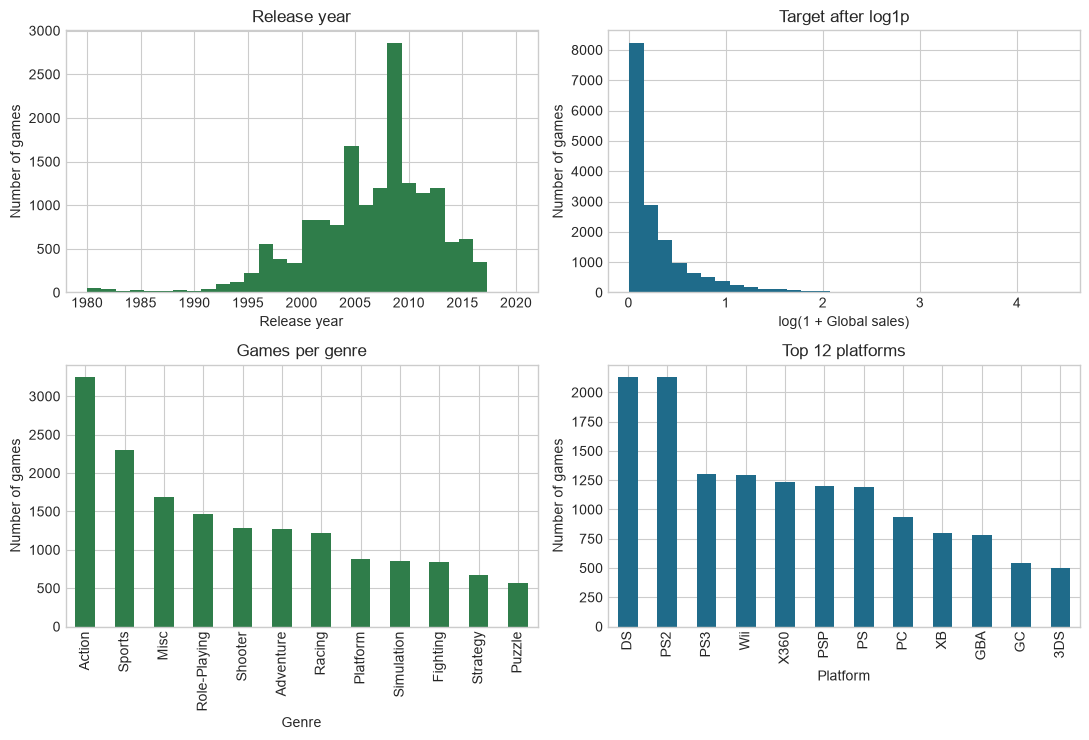

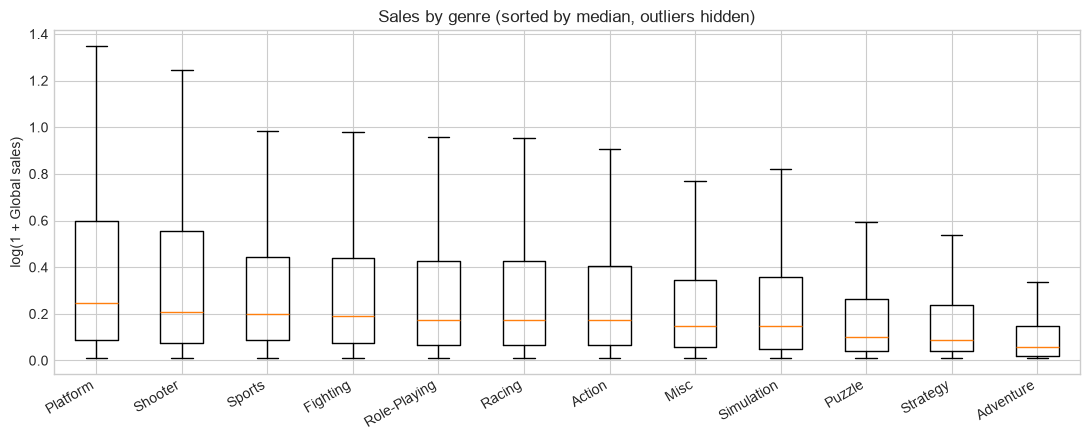

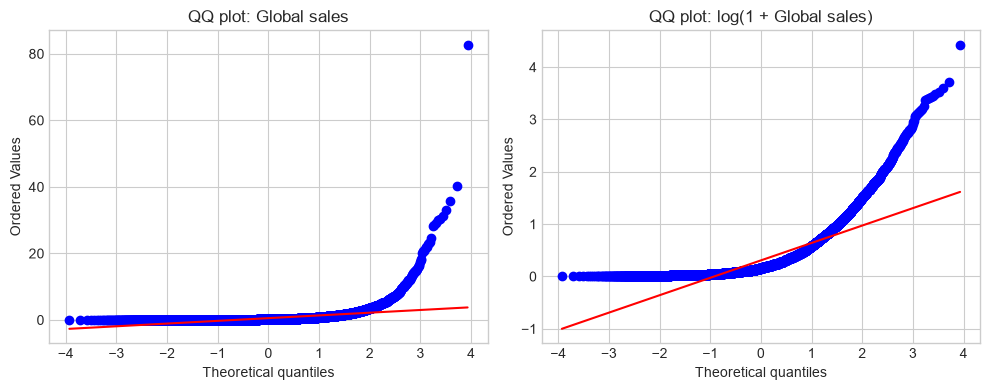

r(Year, Global Sales) = -0.075
r(Year, log sales) = -0.129
มัธยฐานยอดขายตามประเภทเกม (ล้านชุด):


,median sales
Genre,
Platform,0.280
Shooter,0.230
Sports,0.220
Fighting,0.210
Role-Playing,0.190
Racing,0.190
Action,0.190
Misc,0.160
Simulation,0.160


In [7]:
# ─── Descriptive statistics และการกระจาย ───
# วัตถุประสงค์: สรุป mean, median, std, skewness, kurtosis และตรวจ normality ด้วย histogram, boxplot และ QQ plot
summary_cols = ["Year", "Global_Sales", "log_sales", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
desc = work[summary_cols].describe().T
desc["median"] = work[summary_cols].median()
desc["skewness"] = work[summary_cols].skew()
desc["excess kurtosis"] = work[summary_cols].kurtosis()
display(desc.round(3))
print("จำนวนเกมตั้งแต่ปี 2014:", work["Year"].value_counts().sort_index().loc[2014:].to_dict())

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
axes[0, 0].hist(work["Year"], bins=30, color="#2f7d4a")
axes[0, 0].set_xlabel("Release year")
axes[0, 0].set_ylabel("Number of games")
axes[0, 0].set_title("Release year")
axes[0, 1].hist(work["log_sales"], bins=30, color="#1f6b8a")
axes[0, 1].set_xlabel("log(1 + Global sales)")
axes[0, 1].set_ylabel("Number of games")
axes[0, 1].set_title("Target after log1p")
work["Genre"].value_counts().plot.bar(ax=axes[1, 0], color="#2f7d4a")
axes[1, 0].set_ylabel("Number of games")
axes[1, 0].set_title("Games per genre")
work["Platform"].value_counts().head(12).plot.bar(ax=axes[1, 1], color="#1f6b8a")
axes[1, 1].set_ylabel("Number of games")
axes[1, 1].set_title("Top 12 platforms")
plt.tight_layout()
plt.show()

genre_order = work.groupby("Genre")["log_sales"].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 4.5))
plt.boxplot([work.loc[work["Genre"] == g, "log_sales"] for g in genre_order], showfliers=False)
plt.xticks(range(1, len(genre_order) + 1), genre_order, rotation=30, ha="right")
plt.ylabel("log(1 + Global sales)")
plt.title("Sales by genre (sorted by median, outliers hidden)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(work["Global_Sales"], dist="norm", plot=axes[0])
axes[0].set_title("QQ plot: Global sales")
stats.probplot(work["log_sales"], dist="norm", plot=axes[1])
axes[1].set_title("QQ plot: log(1 + Global sales)")
plt.tight_layout()
plt.show()

print("r(Year, Global Sales) = {:.3f}".format(work["Year"].corr(work["Global_Sales"])))
print("r(Year, log sales) = {:.3f}".format(work["Year"].corr(work["log_sales"])))
print("มัธยฐานยอดขายตามประเภทเกม (ล้านชุด):")
display(work.groupby("Genre")["Global_Sales"].median().sort_values(ascending=False).to_frame("median sales"))

In [8]:
# ─── แบ่ง train/test และล็อก test ไว้ ───
# วัตถุประสงค์: ใช้ train สำหรับเลือก feature, ดู bias-variance และเลือกโมเดลทั้งหมด ส่วน test ใช้ครั้งเดียวตอนท้าย Part 5
train_idx, test_idx = train_test_split(np.arange(len(work)), test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("train:", len(train_idx), "เกม | test:", len(test_idx), "เกม")

train: 13032 เกม | test: 3259 เกม


,r with log sales
Publisher_group_Nintendo,0.291
Publisher_group_Other,-0.240
Publisher_group_Electronic Arts,0.140
Year,-0.133
Platform_NES,0.133
Genre_Adventure,-0.130
Platform_GB,0.114
Platform_PSP,-0.094
Publisher_group_Sony Computer Entertainment,0.091
Platform_DS,-0.090


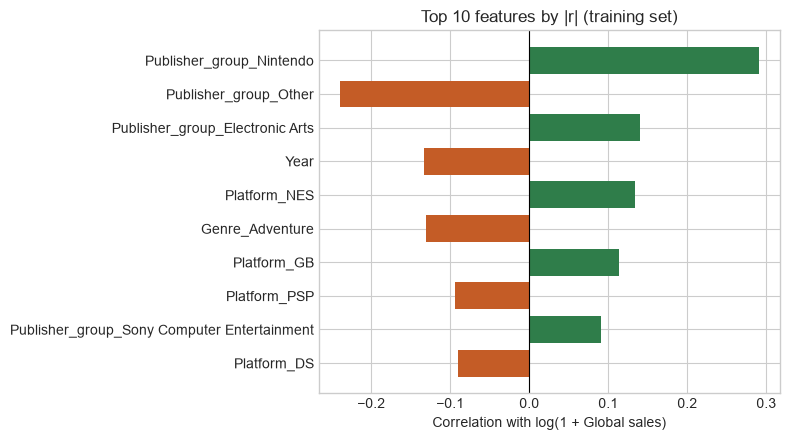

In [9]:
# ─── สหสัมพันธ์ของแต่ละ feature กับ log sales (เฉพาะ train) ───
# วัตถุประสงค์: หา features ที่สัมพันธ์กับเป้าหมายมากที่สุด พร้อมทิศทางของความสัมพันธ์
feature_corr = (
    X_df.iloc[train_idx]
    .corrwith(work["log_sales"].iloc[train_idx])
    .sort_values(key=np.abs, ascending=False)
)
top_corr = feature_corr.head(10)
display(top_corr.round(3).to_frame("r with log sales"))

plt.figure(figsize=(8, 4.5))
bar_colors = ["#2f7d4a" if value > 0 else "#c45c26" for value in top_corr.values[::-1]]
plt.barh(top_corr.index[::-1], top_corr.values[::-1], color=bar_colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with log(1 + Global sales)")
plt.title("Top 10 features by |r| (training set)")
plt.tight_layout()
plt.show()

**Hypothesis testing** (ระดับนัยสำคัญ α = 0.05)

1. **Chi-square test of independence**
   - H₀: ประเภทเกมไม่สัมพันธ์กับการที่เกมขายได้เกินมัธยฐาน (0.17 ล้านชุด)
   - H₁: ประเภทเกมสัมพันธ์กับการที่เกมขายได้เกินมัธยฐาน

2. **Welch two-sample t-test**
   - H₀: ค่าเฉลี่ยของ log(1 + ยอดขาย) ของเกมที่ออกก่อนปี 2000 เท่ากับเกมที่ออกตั้งแต่ปี 2000
   - H₁: ค่าเฉลี่ยของสองกลุ่มไม่เท่ากัน
   - ใช้ Welch เพราะไม่สมมติว่าความแปรปรวนของสองกลุ่มเท่ากัน และสองกลุ่มมีเกม 1,974 กับ 14,317 เกม ค่าเฉลี่ยของแต่ละกลุ่มจึงมีการแจกแจงใกล้ปกติตาม Central Limit Theorem แม้ข้อมูลเดิมจะเบ้

In [10]:
# ─── Hypothesis tests ───
# วัตถุประสงค์: ทดสอบว่าประเภทเกมและยุคที่วางจำหน่ายเกี่ยวกับยอดขายหรือไม่ พร้อมขนาดผล (effect size)
alpha_level = 0.05
median_sales = work["Global_Sales"].median()
high_sales = (work["Global_Sales"] > median_sales).astype(int)
contingency = pd.crosstab(work["Genre"], high_sales)
chi2, chi_p, chi_dof, expected = stats.chi2_contingency(contingency)
cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * (min(contingency.shape) - 1)))

print("มัธยฐานยอดขาย = {} ล้านชุด".format(median_sales))
print("Chi-square = {:.2f}, df = {}, p-value = {:.2e}".format(chi2, chi_dof, chi_p))
print("expected count ต่ำสุด = {:.1f} (เงื่อนไขของ chi-square คือไม่ต่ำกว่า 5)".format(expected.min()))
print("Cramér's V = {:.3f}".format(cramers_v))
print("ผล:", "ปฏิเสธ H0" if chi_p < alpha_level else "ไม่ปฏิเสธ H0")
share_high = (contingency[1] / contingency.sum(axis=1)).sort_values(ascending=False)
display(share_high.round(3).to_frame("share above median"))

before = work.loc[work["Year"] < 2000, "log_sales"]
after = work.loc[work["Year"] >= 2000, "log_sales"]
ttest = stats.ttest_ind(before, after, equal_var=False)
pooled_sd = np.sqrt(
    ((len(before) - 1) * before.var() + (len(after) - 1) * after.var())
    / (len(before) + len(after) - 2)
)
cohen_d = (before.mean() - after.mean()) / pooled_sd

print("\nก่อนปี 2000: n = {}, mean log sales = {:.3f} (แปลงกลับ ≈ {:.2f} ล้านชุด)".format(len(before), before.mean(), np.expm1(before.mean())))
print("ตั้งแต่ปี 2000: n = {}, mean log sales = {:.3f} (แปลงกลับ ≈ {:.2f} ล้านชุด)".format(len(after), after.mean(), np.expm1(after.mean())))
print("Welch t = {:.2f}, p-value = {:.2e}, Cohen's d = {:.2f}".format(ttest.statistic, ttest.pvalue, cohen_d))
print("ผล:", "ปฏิเสธ H0" if ttest.pvalue < alpha_level else "ไม่ปฏิเสธ H0")
print("สัดส่วนเกมที่ขายได้ไม่ถึง 0.1 ล้านชุด: ก่อนปี 2000 = {:.1%} | ตั้งแต่ปี 2000 = {:.1%}".format(
    (work.loc[work["Year"] < 2000, "Global_Sales"] < 0.1).mean(),
    (work.loc[work["Year"] >= 2000, "Global_Sales"] < 0.1).mean()))

มัธยฐานยอดขาย = 0.17 ล้านชุด
Chi-square = 613.88, df = 11, p-value = 1.50e-124
expected count ต่ำสุด = 282.1 (เงื่อนไขของ chi-square คือไม่ต่ำกว่า 5)
Cramér's V = 0.194
ผล: ปฏิเสธ H0


,share above median
Genre,
Platform,0.593
Sports,0.576
Shooter,0.564
Fighting,0.541
Action,0.527
Racing,0.522
Role-Playing,0.512
Simulation,0.486
Misc,0.474



ก่อนปี 2000: n = 1974, mean log sales = 0.432 (แปลงกลับ ≈ 0.54 ล้านชุด)
ตั้งแต่ปี 2000: n = 14317, mean log sales = 0.290 (แปลงกลับ ≈ 0.34 ล้านชุด)
Welch t = 12.65, p-value = 1.53e-35, Cohen's d = 0.36
ผล: ปฏิเสธ H0
สัดส่วนเกมที่ขายได้ไม่ถึง 0.1 ล้านชุด: ก่อนปี 2000 = 21.1% | ตั้งแต่ปี 2000 = 36.7%


**Bias-Variance: Train MSE เทียบกับ Validation MSE**

เพิ่มความซับซ้อนของโมเดลเชิงเส้นทีละขั้น ตั้งแต่ใช้ Year ตัวเดียว เพิ่ม Genre, Platform, Publisher แล้วเพิ่ม interaction ระหว่างหมวดหมู่ ทุกขั้นวัดด้วย 5-fold CV บน train เท่านั้น ค่า “Validation MSE” ทำหน้าที่แทน Test MSE ในกราฟ bias-variance เพราะ test set ต้องถูกล็อกไว้จนเลือกโมเดลเสร็จ ถ้านำ test มาใช้ตรงนี้ ผลสุดท้ายจะดูดีเกินจริง

ทุกขั้นใช้ Ridge ที่ α = 1 แทน least squares ธรรมดา เพราะแพลตฟอร์มบางเครื่องมีเกมน้อยมาก (PCFX และ GG มีเครื่องละ 1 เกม TG16 มี 2 เกม) บาง fold จึงไม่มีเกมของเครื่องนั้นเลย dummy กลายเป็นศูนย์ทั้งคอลัมน์ และเมื่อเพิ่ม interaction ก็มี dummy ที่ซ้ำกันพอดี X จึงไม่ full rank และ XᵀX ไม่มี inverse ผลของ least squares ธรรมดาจึงขึ้นกับเวอร์ชันของไลบรารี เมื่อทดลองรันด้วย scikit-learn 1.5.2 กับ SciPy 1.14.1 Validation MSE ของ least squares ธรรมดาพุ่งถึงระดับ 10²⁵ การเพิ่ม αI ทำให้ XᵀX + αI มี inverse เสมอ ส่วน α = 1 เล็กมากเมื่อเทียบกับผลรวมกำลังสองของแต่ละคอลัมน์ที่ standardize แล้ว (ประมาณ 10,400 ใน train ของแต่ละ fold) ผลจึงแทบเท่ากับ least squares ขั้น “+ Publisher” ของกราฟนี้จึงเป็นโมเดลเดียวกับ Model 3 ใน Part 4

แพลตฟอร์มที่มีไม่ถึง 5 เกม: {'3DO': 3, 'TG16': 2, 'GG': 1, 'PCFX': 1}


,Features,Train MSE,Validation MSE,Validation SE,Gap
Model,,,,,
Year,1,0.1534,0.1534,0.0057,0.0001
+ Genre,12,0.1486,0.1491,0.0053,0.0004
+ Platform,42,0.1372,0.1385,0.0050,0.0014
+ Publisher,57,0.1171,0.1187,0.0047,0.0016
+ Genre x Platform,349,0.1117,0.1187,0.0047,0.0070
+ all pairwise,813,0.1005,0.1155,0.0047,0.0150


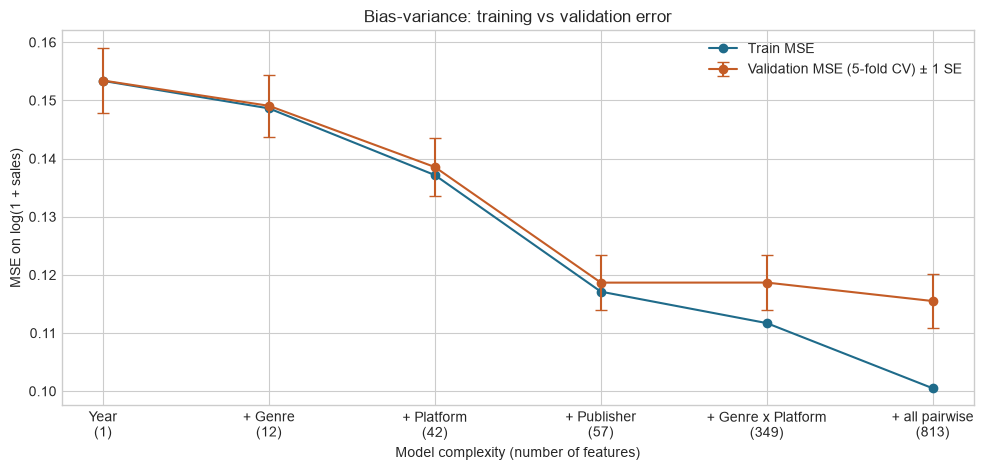

In [11]:
# ─── Bias-Variance: error ตามความซับซ้อนของโมเดล ───
# วัตถุประสงค์: ดูว่าเมื่อเพิ่มตัวแปรและ interaction แล้ว error บนข้อมูลที่โมเดลไม่เห็นยังลดลงหรือไม่
genre_x_platform = (work["Genre"] + " x " + work["Platform"]).rename("Genre_x_Platform")
genre_x_publisher = (work["Genre"] + " x " + work["Publisher_group"]).rename("Genre_x_Publisher")
platform_x_publisher = (work["Platform"] + " x " + work["Publisher_group"]).rename("Platform_x_Publisher")

complexity_levels = {
    "Year": work[["Year"]],
    "+ Genre": work[["Year", "Genre"]],
    "+ Platform": work[["Year", "Genre", "Platform"]],
    "+ Publisher": work[features],
    "+ Genre x Platform": pd.concat([work[features], genre_x_platform], axis=1),
    "+ all pairwise": pd.concat(
        [work[features], genre_x_platform, genre_x_publisher, platform_x_publisher], axis=1
    ),
}

bv_rows = []
for name, frame in complexity_levels.items():
    X_level = pd.get_dummies(frame, drop_first=True, dtype=float).to_numpy()
    # α = 1 ทำให้ XᵀX + αI มี inverse เสมอ แม้บาง fold จะมี dummy ที่เป็นศูนย์ทั้งคอลัมน์หรือซ้ำกัน
    result = cross_validate(
        make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        X_level[train_idx], y[train_idx], cv=cv,
        scoring="neg_mean_squared_error", return_train_score=True,
    )
    validation_mse = -result["test_score"]
    bv_rows.append({
        "Model": name,
        "Features": X_level.shape[1],
        "Train MSE": -result["train_score"].mean(),
        "Validation MSE": validation_mse.mean(),
        "Validation SE": validation_mse.std(ddof=1) / np.sqrt(len(validation_mse)),
    })

platform_counts = work["Platform"].value_counts()
print("แพลตฟอร์มที่มีไม่ถึง 5 เกม:", platform_counts[platform_counts < 5].to_dict())

bias_variance = pd.DataFrame(bv_rows).set_index("Model")
bias_variance["Gap"] = bias_variance["Validation MSE"] - bias_variance["Train MSE"]
display(bias_variance.round(4))

positions = np.arange(len(bias_variance))
tick_labels = ["{}\n({})".format(name, n) for name, n in zip(bias_variance.index, bias_variance["Features"])]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(positions, bias_variance["Train MSE"], marker="o", color="#1f6b8a", label="Train MSE")
ax.errorbar(
    positions, bias_variance["Validation MSE"], yerr=bias_variance["Validation SE"],
    marker="o", color="#c45c26", capsize=4, label="Validation MSE (5-fold CV) ± 1 SE",
)
ax.set_xticks(positions)
ax.set_xticklabels(tick_labels)
ax.set_xlabel("Model complexity (number of features)")
ax.set_ylabel("MSE on log(1 + sales)")
ax.set_title("Bias-variance: training vs validation error")
ax.legend()
plt.tight_layout()
plt.show()

**Insight จาก CLO2 Analysis:**

- **Distribution ของ target:** Global Sales มีค่าเฉลี่ย 0.54 ล้านชุด แต่มัธยฐานเพียง 0.17 ล้านชุด skewness 17.3 และ excess kurtosis 596 (การแจกแจงปกติมีค่าทั้งสองเป็น 0) QQ plot ของยอดขายดิบโค้งออกจากเส้นปกติชัดเจน หลัง log1p แล้ว skewness ลดเหลือ 2.75 ยังไม่ปกติสมบูรณ์แต่เหมาะกับ least squares มากกว่าเดิม
- **Features สำคัญ:** ใน train ตัวแปรที่สัมพันธ์กับ log sales สูงสุดคือการเป็นเกมของ Nintendo (r = 0.29) รองลงมาคือกลุ่มค่ายเล็ก Other ในทิศตรงข้าม (r = −0.24) Electronic Arts (0.14) และ Year (−0.13) จึงเห็นว่าค่ายผู้จัดจำหน่ายสำคัญกว่าปีที่ออก
- **Chi-square:** χ² = 613.9 (df = 11) และ p-value = 1.5 × 10⁻¹²⁴ แปลว่าถ้าประเภทเกมไม่เกี่ยวกับยอดขายจริง โอกาสที่จะเห็นความต่างระหว่างประเภทมากขนาดนี้แทบเป็นศูนย์ p-value ต่ำกว่า α = 0.05 จึงปฏิเสธ H₀ ประเภทเกมสัมพันธ์กับโอกาสขายเกินมัธยฐาน (expected count ต่ำสุด 282 จึงใช้ chi-square ได้) เกม Platform (59%), Sports (58%) และ Shooter (56%) ขายเกินมัธยฐานบ่อยที่สุด ส่วน Adventure มีเพียง 23% แต่ Cramér's V = 0.19 แปลว่าความสัมพันธ์มีจริงแต่ไม่แรง **ในเชิงธุรกิจ** การเลือกทำเกมแนว Platform, Sports หรือ Shooter เพิ่มโอกาสขายเกินมัธยฐานได้ แต่ประเภทเกมอย่างเดียวบอกยอดขายได้ไม่มาก
- **Welch t-test:** t = 12.65 และ p-value = 1.5 × 10⁻³⁵ ต่ำกว่า 0.05 มาก จึงปฏิเสธ H₀ เกมก่อนปี 2000 ในตารางนี้มีค่าเฉลี่ย log sales สูงกว่า (Cohen's d = 0.36 ขนาดผลเล็กถึงปานกลาง) แต่ไม่ได้แปลว่าเกมยุคเก่าขายดีกว่าเสมอ เกมก่อนปี 2000 ที่ขายได้ไม่ถึง 0.1 ล้านชุดมีเพียง 21.1% เทียบกับ 36.7% ของเกมตั้งแต่ปี 2000 แสดงว่าเกมยุคเก่าที่ขายน้อยมักไม่ถูกบันทึกไว้ เกมยุคเก่าที่เหลือในตารางจึงมักเป็นเกมดัง **ในเชิงธุรกิจ** จึงไม่ควรใช้ผลนี้สรุปว่าเกมยุคใหม่ขายได้น้อยลงเอง เพราะความต่างส่วนหนึ่งมาจากวิธีเก็บข้อมูล
- **Bias-Variance:** Train MSE ลดลงทุกครั้งที่เพิ่มความซับซ้อน Validation MSE ลดชัดจนถึงขั้น “+ Publisher” (57 features) หลังจากนั้นเพิ่ม Genre × Platform อีกกว่า 290 คอลัมน์แต่ Validation MSE แทบไม่ลด ขณะที่ช่องว่าง Train–Validation กว้างขึ้นจาก 0.002 เป็น 0.007 และ 0.015 คือ variance เริ่มเพิ่ม ขั้น “+ all pairwise” (813 features) ลด Validation MSE ได้อีกเพียง 0.003 ซึ่งน้อยกว่า 1 SE ความซับซ้อนที่เหมาะจึงอยู่ที่ main effects 57 features ซึ่งใช้ต่อใน Part 4

---
## Part 4: CLO3 — Model Building

ในส่วนนี้ให้สร้าง Regression หรือ Classification model อย่างน้อย 2 models

**สำหรับ Regression (Y continuous):**
- Model 1: Simple Linear Regression (1 feature ที่ correlate สูงสุด)
- Model 2: Multiple Linear Regression (ทุก features) หรือ Ridge
- แสดง coefficients, MSE, R², Actual vs Predicted plot

**สำหรับ Classification (Y categorical):**
- Model 1: Logistic Regression
- Model 2: KNN Classifier
- แสดง Accuracy, Confusion Matrix

**Dataset ของกลุ่มเหมาะกับ:** ✅ Regression  ⬜ Classification

**Data preparation**
- Train/Test split: 80% / 20% (13,032 / 3,259 เกม) แบบสุ่มด้วย `random_state = 42` แบ่งก่อนเลือก feature และก่อนเลือกโมเดล
- Encoding: one-hot ของ Genre, Platform และ Publisher_group ด้วย `drop_first=True` ได้ 57 features
- Scaling: ทุกโมเดลมี `StandardScaler` อยู่ใน pipeline ก่อนเข้าโมเดล
- Target: log(1 + Global Sales)

| Model | ตัวแปรต้น | เหตุผล |
|-------|-----------|--------|
| Model 1: Simple Linear Regression | feature เดียวที่ค่าสัมบูรณ์ของ r สูงสุดใน train | baseline ที่ง่ายที่สุด ตามที่ template กำหนด |
| Model 2: Polynomial Regression ระดับ 2 | Year และ Year² | Year เป็นตัวแปรต่อเนื่องเพียงตัวเดียว จึงใช้ทดสอบว่าความสัมพันธ์กับปีเป็นเส้นโค้งหรือไม่ |
| Model 3: Ridge Regression (α = 1) | Year + Genre + Platform + Publisher (57 features) | ใช้ทุกตัวแปรตามผล bias-variance และลงโทษ coefficient ไม่ให้ใหญ่เกินไป |

ค่า Validation ด้านล่างมาจาก out-of-fold prediction ของ 5-fold CV บน train ยังไม่ใช้ test set ใน Part นี้ ผล test ของโมเดลที่เลือกอยู่ท้าย Part 5

Model 1 ใช้ feature ที่ |r| สูงสุดใน train: Publisher_group_Nintendo (r = 0.291)


,Train MSE,Train RMSE,Train R²,Validation MSE,Validation RMSE,Validation R²
Model,,,,,,
Model 1: Simple Linear,0.1429,0.3781,0.0845,0.1431,0.3783,0.0836
Model 2: Polynomial Year (deg 2),0.1525,0.3906,0.0231,0.1526,0.3907,0.0226
"Model 3: Ridge (all features, alpha=1)",0.1173,0.3424,0.2490,0.1187,0.3445,0.2400



Model 1: log(1 + sales) = 0.283 + 0.565 × Publisher_group_Nintendo
  ค่าทำนายแปลงกลับ: Publisher_group_Nintendo = 0 ≈ 0.33 ล้านชุด | Publisher_group_Nintendo = 1 ≈ 1.33 ล้านชุด

Model 2: log(1 + sales) = 0.290 + (-0.0355)·z + (0.0172)·z²   โดย z คือ Year ที่ standardize แล้ว

Model 3: intercept = 0.308 | coefficient ที่ค่าสัมบูรณ์สูงสุด (ต่อ 1 SD ของ feature)


,coefficient
Platform_PS3,0.098
Year,-0.095
Publisher_group_Nintendo,0.090
Platform_X360,0.090
Publisher_group_Other,-0.087
Platform_PS2,0.075
Platform_PS4,0.066
Platform_Wii,0.066
Platform_DS,0.049
Publisher_group_Namco Bandai Games,-0.042


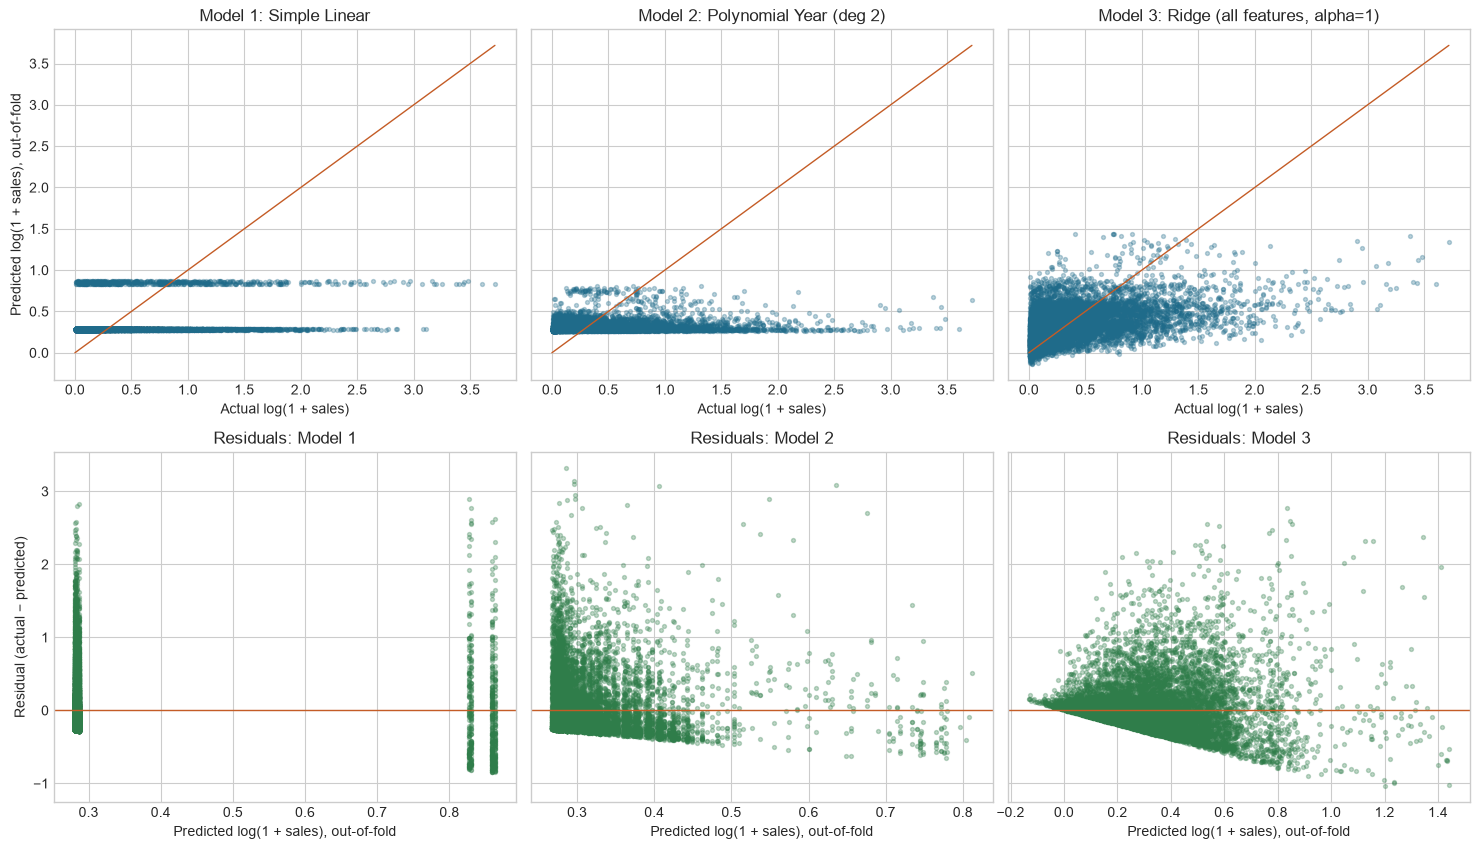

In [12]:
# ─── สร้าง 3 โมเดลและวัดผลบน train ───
# วัตถุประสงค์: fit โมเดล อ่าน coefficient และวัด MSE, RMSE, R² ทั้งบน train และ validation (out-of-fold) พร้อม residual plot
best_feature = feature_corr.index[0]
print("Model 1 ใช้ feature ที่ |r| สูงสุดใน train:", best_feature, "(r = {:.3f})".format(feature_corr.iloc[0]))

X_simple = X_df[[best_feature]].to_numpy()
X_year = work[["Year"]].to_numpy()
X_all = X_df.to_numpy()

model_names = [
    "Model 1: Simple Linear",
    "Model 2: Polynomial Year (deg 2)",
    "Model 3: Ridge (all features, alpha=1)",
]
models = {
    model_names[0]: (make_pipeline(StandardScaler(), LinearRegression()), X_simple),
    model_names[1]: (
        make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
        X_year,
    ),
    model_names[2]: (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), X_all),
}

comparison_rows = []
oof_predictions = {}
for name, (model, X_model) in models.items():
    model.fit(X_model[train_idx], y[train_idx])
    train_pred = model.predict(X_model[train_idx])
    oof_pred = cross_val_predict(model, X_model[train_idx], y[train_idx], cv=cv)
    oof_predictions[name] = oof_pred
    train_mse = mean_squared_error(y[train_idx], train_pred)
    validation_mse = mean_squared_error(y[train_idx], oof_pred)
    comparison_rows.append({
        "Model": name,
        "Train MSE": train_mse,
        "Train RMSE": np.sqrt(train_mse),
        "Train R²": r2_score(y[train_idx], train_pred),
        "Validation MSE": validation_mse,
        "Validation RMSE": np.sqrt(validation_mse),
        "Validation R²": r2_score(y[train_idx], oof_pred),
    })
comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison.round(4))

scaler_1 = models[model_names[0]][0].named_steps["standardscaler"]
linear_1 = models[model_names[0]][0].named_steps["linearregression"]
slope_1 = linear_1.coef_[0] / scaler_1.scale_[0]
intercept_1 = linear_1.intercept_ - slope_1 * scaler_1.mean_[0]
print("\nModel 1: log(1 + sales) = {:.3f} + {:.3f} × {}".format(intercept_1, slope_1, best_feature))
print("  ค่าทำนายแปลงกลับ: {0} = 0 ≈ {1:.2f} ล้านชุด | {0} = 1 ≈ {2:.2f} ล้านชุด".format(
    best_feature, np.expm1(intercept_1), np.expm1(intercept_1 + slope_1)))

linear_2 = models[model_names[1]][0].named_steps["linearregression"]
print("\nModel 2: log(1 + sales) = {:.3f} + ({:.4f})·z + ({:.4f})·z²   โดย z คือ Year ที่ standardize แล้ว".format(
    linear_2.intercept_, linear_2.coef_[0], linear_2.coef_[1]))

ridge_1 = models[model_names[2]][0].named_steps["ridge"]
ridge_coef = pd.Series(ridge_1.coef_, index=X_df.columns)
print("\nModel 3: intercept = {:.3f} | coefficient ที่ค่าสัมบูรณ์สูงสุด (ต่อ 1 SD ของ feature)".format(ridge_1.intercept_))
display(ridge_coef.reindex(ridge_coef.abs().sort_values(ascending=False).head(10).index).round(3).to_frame("coefficient"))

fig, axes = plt.subplots(2, 3, figsize=(15, 8.6), sharey="row")
line_limits = [0, y[train_idx].max()]
for col, (name, pred) in enumerate(oof_predictions.items()):
    axes[0, col].scatter(y[train_idx], pred, s=8, alpha=0.3, color="#1f6b8a")
    axes[0, col].plot(line_limits, line_limits, color="#c45c26", linewidth=1)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Actual log(1 + sales)")

    axes[1, col].scatter(pred, y[train_idx] - pred, s=8, alpha=0.3, color="#2f7d4a")
    axes[1, col].axhline(0, color="#c45c26", linewidth=1)
    axes[1, col].set_title("Residuals: " + name.split(":")[0])
    axes[1, col].set_xlabel("Predicted log(1 + sales), out-of-fold")
axes[0, 0].set_ylabel("Predicted log(1 + sales), out-of-fold")
axes[1, 0].set_ylabel("Residual (actual − predicted)")
plt.tight_layout()
plt.show()

**สรุป Model Comparison:**

| Model | Train Metric (MSE / RMSE / R²) | Validation Metric (5-fold CV, MSE / RMSE / R²) | รายละเอียด |
|-------|--------------------------------|------------------------------------------------|-----------|
| Model 1: Simple Linear | 0.1429 / 0.3781 / 0.0845 | 0.1431 / 0.3783 / 0.0836 | ใช้ dummy ว่าเป็นเกม Nintendo หรือไม่ ทำนายได้เพียงสองค่า |
| Model 2: Polynomial Year (deg 2) | 0.1525 / 0.3906 / 0.0231 | 0.1526 / 0.3907 / 0.0226 | ส่วนโค้งของปีช่วยน้อยมาก |
| Model 3: Ridge (all features, α = 1) | 0.1173 / 0.3424 / 0.2490 | 0.1187 / 0.3445 / 0.2400 | ใช้ทั้งปี ประเภท แพลตฟอร์ม และค่าย |

**Insight:**

- **Metric ที่ใช้:** ใช้ MSE เป็นเกณฑ์หลัก เพราะเป็นค่าที่ least squares ทำให้ต่ำสุด และเป็นเกณฑ์เดียวกับ CV ใน Part 5 RMSE คือรากของ MSE จึงอยู่ในหน่วยเดียวกับเป้าหมาย คือ log(1 + ล้านชุด) ส่วน R² บอกสัดส่วน variance ที่โมเดลอธิบายได้ จึงใช้เทียบข้ามโมเดลได้ง่าย
- **Model 1** บอกว่าเกมของ Nintendo มี log(1 + ยอดขาย) สูงกว่าเกมอื่นเฉลี่ย 0.565 หน่วย เมื่อแปลงกลับคือประมาณ 1.33 ล้านชุดเทียบกับ 0.33 ล้านชุด แต่ R² ประมาณ 0.08 เพราะ dummy ตัวเดียวแบ่งเกมได้เพียงสองกลุ่ม กราฟ Actual vs Predicted จึงเป็นเส้นแนวนอนสองเส้น
- **Model 2** มี R² ประมาณ 0.02 coefficient ของ z เป็นลบ แปลว่าเกมที่ออกปีหลังมีแนวโน้มยอดขายต่ำกว่า ส่วนพจน์ z² ทำให้เส้นโค้งเพียงเล็กน้อย ปีที่วางจำหน่ายอย่างเดียวจึงอธิบายยอดขายได้น้อย
- **Model 3** ดีที่สุด Validation MSE 0.1187 ต่ำกว่า Model 1 ประมาณ 17% และ R² ประมาณ 0.24 coefficient ที่เป็นบวกมากคือ PS3, Nintendo, X360, PS2 ส่วนที่เป็นลบคือ Year และกลุ่มค่ายเล็ก Other ค่าเหล่านี้เทียบกับหมวดอ้างอิง Action, Atari 2600 และ Activision และเป็นผลต่อ 1 SD ของ feature
- ทั้งสามโมเดลมี Train MSE กับ Validation MSE ใกล้กันมาก จึงไม่มีสัญญาณ overfitting ปัญหาหลักคือ **underfitting / bias**: ตัวแปรที่รู้ก่อนเกมวางขายอธิบาย variance ของ log ยอดขายได้ไม่ถึงหนึ่งในสี่ จุดในกราฟของเกมที่ขายดีมากอยู่ต่ำกว่าเส้นทแยงชัดเจน คือโมเดลทำนายเกมฮิตต่ำเกินไป
- **Residual plot:** ทั้งสามโมเดลมี residual บวกขนาดใหญ่กระจายอยู่ด้านบน คือเกมที่ขายดีกว่าค่าทำนายมาก ส่วนด้านล่างถูกจำกัดไว้ เพราะยอดขายต่ำสุดคือ 0.01 ล้านชุด residual จึงต่ำกว่า log(1.01) − ค่าทำนายไม่ได้ ขอบล่างของ Model 2 และ Model 3 จึงเป็นเส้นตรงเอียงลง ส่วน Model 1 ทำนายได้เพียงสองค่า residual จึงเป็นแถบแนวตั้งสองแถบ residual ของทุกโมเดลเบ้ขวาและไม่สมมาตรรอบศูนย์ แปลว่าโมเดลเชิงเส้นยังจับเกมฮิตไม่ได้
- **ในเชิงธุรกิจ:** ค่ายและเครื่องที่เกมลงช่วยประเมินยอดขายคร่าว ๆ ได้ เช่น เกม Nintendo หรือเกมบน PS2, PS3, X360 มักขายได้มากกว่า แต่ยังไม่พอใช้ประเมินว่าเกมใหม่เกมใดจะเป็นเกมฮิต

---
## Part 5: CLO4 — Model Selection

ในส่วนนี้ให้ใช้ Cross-Validation เพื่อเลือก model ที่ดีที่สุดอย่างเป็นธรรม

**สิ่งที่ต้องทำ:**
- เปรียบเทียบอย่างน้อย 3 models ด้วย 5-Fold Cross-Validation
- Plot bar chart ของ CV MSE (หรือ Accuracy สำหรับ Classification)
- สรุปว่า model ไหนดีที่สุดและทำไม

**ขั้นตอน**
1. ใช้ 5-fold CV (`KFold`, `shuffle=True`, `random_state=42`) บน train เท่านั้น ไม่ใช้ stratified เพราะเป็น regression รายงาน CV MSE เป็นค่าเฉลี่ย ± SE โดย SE = SD ของ MSE ทั้ง 5 fold / √5 ทุกโมเดลมี scaler อยู่ใน pipeline จึง fit scaler ใหม่ในทุก fold
2. ปรับ α ของ Ridge ด้วย CV ช่วง 0.01 ถึง 100,000
3. ใช้ **One-SE Rule**: หาโมเดลที่ CV MSE ต่ำสุด แล้วเลือกโมเดลที่ง่ายที่สุดซึ่ง $\text{CV}(m) \le \text{CV}_{\min} + \text{SE}_{\min}$ ลำดับความง่ายคือ Model 1 → Model 2 → Ridge ที่ α มากไปน้อย เพราะ α ยิ่งมาก coefficient ยิ่งถูกบีบเข้าหาศูนย์
4. Refit โมเดลที่เลือกบน train ทั้งหมด แล้วประเมินบน test **ครั้งเดียว**

,CV MSE,SE
Model,,
Model 1: Simple Linear,0.1431,0.0052
Model 2: Polynomial Year (deg 2),0.1526,0.0056
"Model 3: Ridge (all features, alpha=1)",0.1187,0.0047


,alpha,CV MSE,SE
0,0.01,0.11867,0.00474
1,0.03,0.11867,0.00474
2,0.1,0.11867,0.00474
3,0.3,0.11867,0.00474
4,1,0.11867,0.00474
5,3,0.11867,0.00474
6,10,0.11867,0.00475
7,30,0.11869,0.00476
8,100,0.11874,0.00478
9,300,0.11880,0.00482


โมเดลที่ CV MSE ต่ำสุด: Ridge alpha=1 (CV MSE = 0.11867, SE = 0.00474)
เส้น One-SE = 0.12341
โมเดลที่เลือกตาม One-SE Rule: Ridge alpha=3000 (CV MSE = 0.12043, SE = 0.00506)


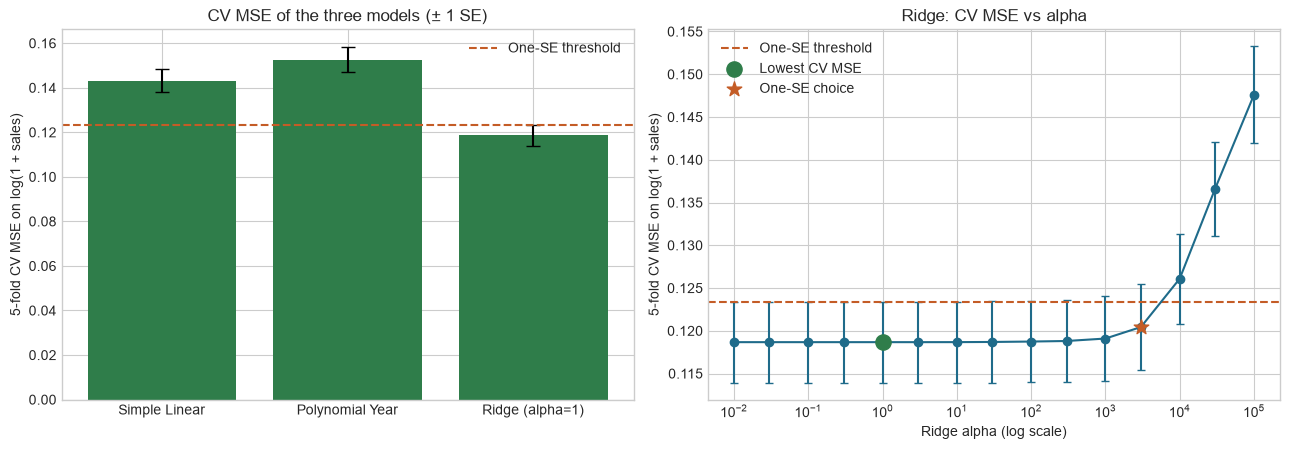

In [13]:
# ─── 5-fold CV ± SE, ปรับ α ของ Ridge และ One-SE Rule ───
# วัตถุประสงค์: เปรียบเทียบโมเดลอย่างเป็นธรรมบน train แล้วเลือกโมเดลที่ง่ายที่สุดที่ยังดีพอ
def cv_mse_se(model, X_model):
    fold_mse = -cross_val_score(
        model, X_model[train_idx], y[train_idx], cv=cv, scoring="neg_mean_squared_error"
    )
    return fold_mse.mean(), fold_mse.std(ddof=1) / np.sqrt(len(fold_mse))


cv_rows = []
for name, (model, X_model) in models.items():
    mean_mse, se = cv_mse_se(model, X_model)
    cv_rows.append({"Model": name, "CV MSE": mean_mse, "SE": se})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results.round(4))

ridge_alphas = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]
ridge_rows = []
for a in ridge_alphas:
    mean_mse, se = cv_mse_se(make_pipeline(StandardScaler(), Ridge(alpha=a)), X_all)
    ridge_rows.append({"alpha": a, "CV MSE": mean_mse, "SE": se})
ridge_path = pd.DataFrame(ridge_rows)
display(ridge_path.assign(alpha=ridge_path["alpha"].map("{:g}".format)).round(5))

candidates = [
    {"name": model_names[0], "cv": cv_results.loc[model_names[0], "CV MSE"], "se": cv_results.loc[model_names[0], "SE"]},
    {"name": model_names[1], "cv": cv_results.loc[model_names[1], "CV MSE"], "se": cv_results.loc[model_names[1], "SE"]},
]
for row in ridge_path.sort_values("alpha", ascending=False).to_dict("records"):
    candidates.append({
        "name": "Ridge alpha={:g}".format(row["alpha"]),
        "alpha": row["alpha"],
        "cv": row["CV MSE"],
        "se": row["SE"],
    })

best = min(candidates, key=lambda c: c["cv"])
threshold = best["cv"] + best["se"]
one_se = next(c for c in candidates if c["cv"] <= threshold)
print("โมเดลที่ CV MSE ต่ำสุด: {} (CV MSE = {:.5f}, SE = {:.5f})".format(best["name"], best["cv"], best["se"]))
print("เส้น One-SE = {:.5f}".format(threshold))
print("โมเดลที่เลือกตาม One-SE Rule: {} (CV MSE = {:.5f}, SE = {:.5f})".format(one_se["name"], one_se["cv"], one_se["se"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
short_names = ["Simple Linear", "Polynomial Year", "Ridge (alpha=1)"]
axes[0].bar(short_names, cv_results["CV MSE"], yerr=cv_results["SE"], capsize=5, color="#2f7d4a")
axes[0].axhline(threshold, color="#c45c26", linestyle="--", label="One-SE threshold")
axes[0].set_ylabel("5-fold CV MSE on log(1 + sales)")
axes[0].set_title("CV MSE of the three models (± 1 SE)")
axes[0].legend()

axes[1].errorbar(ridge_path["alpha"], ridge_path["CV MSE"], yerr=ridge_path["SE"], marker="o", capsize=3, color="#1f6b8a")
axes[1].axhline(threshold, color="#c45c26", linestyle="--", label="One-SE threshold")
if "alpha" in best:
    axes[1].scatter([best["alpha"]], [best["cv"]], s=120, color="#2f7d4a", zorder=3, label="Lowest CV MSE")
if "alpha" in one_se:
    axes[1].scatter([one_se["alpha"]], [one_se["cv"]], s=120, color="#c45c26", marker="*", zorder=3, label="One-SE choice")
axes[1].set_xscale("log")
axes[1].set_xlabel("Ridge alpha (log scale)")
axes[1].set_ylabel("5-fold CV MSE on log(1 + sales)")
axes[1].set_title("Ridge: CV MSE vs alpha")
axes[1].legend()
plt.tight_layout()
plt.show()

,MSE,RMSE,R²,RMSE (million units)
Train,0.1189,0.3448,0.2388,1.3455
Test,0.1309,0.3617,0.2113,2.0236


CV MSE ของโมเดลที่เลือก = 0.1204 ± 0.0051 | Test MSE = 0.1309
Effective degrees of freedom ของ Ridge: alpha = 1 → 57.0 | alpha = 3000 → 44.4 (จาก 57 coefficients)

เกมที่ขายดีที่สุด 5 อันดับใน test set เทียบกับค่าทำนาย (ล้านชุด)


,Name,Platform,Year,Genre,Publisher,Global_Sales,Predicted_Sales
0,Wii Sports,Wii,2006,Sports,Nintendo,82.74,1.09
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,33.00,1.05
8,New Super Mario Bros. Wii,Wii,2009,Platform,Nintendo,28.62,1.25
14,Wii Fit Plus,Wii,2009,Sports,Nintendo,22.00,1.05
15,Kinect Adventures!,X360,2010,Misc,Microsoft Game Studios,21.82,0.32


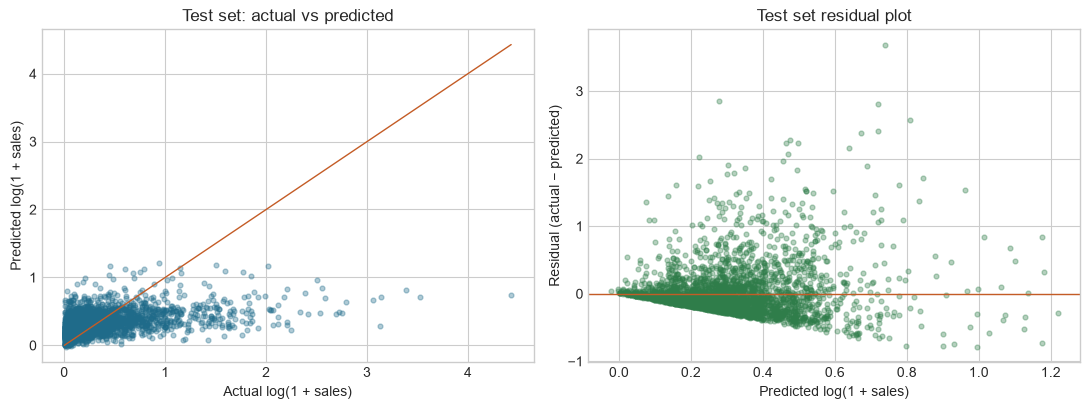

In [14]:
# ─── ประเมินโมเดลที่เลือกบน test set ครั้งเดียว ───
# วัตถุประสงค์: refit บน train ทั้งหมด รายงาน MSE, RMSE, R² บน test และเทียบกับ CV
final_alpha = one_se["alpha"]
final_model = make_pipeline(StandardScaler(), Ridge(alpha=final_alpha))
final_model.fit(X_all[train_idx], y[train_idx])
pred_train = final_model.predict(X_all[train_idx])
pred_test = final_model.predict(X_all[test_idx])


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_pred),
        "RMSE (million units)": np.sqrt(mean_squared_error(np.expm1(y_true), np.expm1(y_pred))),
    }


final_table = pd.DataFrame({
    "Train": regression_metrics(y[train_idx], pred_train),
    "Test": regression_metrics(y[test_idx], pred_test),
}).T
display(final_table.round(4))
print("CV MSE ของโมเดลที่เลือก = {:.4f} ± {:.4f} | Test MSE = {:.4f}".format(
    one_se["cv"], one_se["se"], final_table.loc["Test", "MSE"]))

X_train_scaled = final_model.named_steps["standardscaler"].transform(X_all[train_idx])
singular_values = np.linalg.svd(X_train_scaled, compute_uv=False)


def ridge_effective_df(a):
    return np.sum(singular_values**2 / (singular_values**2 + a))


print("Effective degrees of freedom ของ Ridge: alpha = {:g} → {:.1f} | alpha = {:g} → {:.1f} (จาก 57 coefficients)".format(
    best.get("alpha", 1.0), ridge_effective_df(best.get("alpha", 1.0)), final_alpha, ridge_effective_df(final_alpha)))

test_view = work.iloc[test_idx][["Name", "Platform", "Year", "Genre", "Publisher", "Global_Sales"]].copy()
test_view["Predicted_Sales"] = np.expm1(pred_test)
print("\nเกมที่ขายดีที่สุด 5 อันดับใน test set เทียบกับค่าทำนาย (ล้านชุด)")
display(test_view.sort_values("Global_Sales", ascending=False).head(5).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(y[test_idx], pred_test, alpha=0.35, s=12, color="#1f6b8a")
limits = [0, max(y[test_idx].max(), pred_test.max())]
axes[0].plot(limits, limits, color="#c45c26", linewidth=1)
axes[0].set_xlabel("Actual log(1 + sales)")
axes[0].set_ylabel("Predicted log(1 + sales)")
axes[0].set_title("Test set: actual vs predicted")

residuals = y[test_idx] - pred_test
axes[1].scatter(pred_test, residuals, alpha=0.35, s=12, color="#2f7d4a")
axes[1].axhline(0, color="#c45c26", linewidth=1)
axes[1].set_xlabel("Predicted log(1 + sales)")
axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Test set residual plot")
plt.tight_layout()
plt.show()

**Best Model จาก Cross-Validation:** Ridge ที่ใช้ Year, Genre, Platform และ Publisher โดยเลือก **α = 3000** ตาม One-SE Rule

**เหตุผล:**

- **เทียบสามโมเดล:** Ridge (α = 1) ได้ CV MSE 0.1187 ± 0.0047 ต่ำกว่า Simple Linear (0.1431 ± 0.0052) และ Polynomial Year (0.1526 ± 0.0056) ชัดเจน สองโมเดลหลังอยู่เหนือเส้น One-SE จึงถูกตัดออก
- **ปรับ α:** CV MSE แทบเท่าเดิมตั้งแต่ α = 0.01 ถึงประมาณ 100 (ประมาณ 0.1187) แล้วเริ่มสูงขึ้นเมื่อ α มากขึ้น เส้น One-SE อยู่ที่ 0.1234 α ที่มากที่สุดที่ยังอยู่ใต้เส้นคือ 3000 (CV MSE 0.1204 ± 0.0051) ส่วน α = 10,000 ได้ 0.1261 ซึ่งเกินเส้น
- **ทำไมเลือก α = 3000 แทน α ที่ CV ต่ำสุด:** ผลต่าง CV MSE ระหว่างสองค่าน้อยกว่า 1 SE จึงแยกไม่ออกทางสถิติ แต่ α = 3000 บีบ coefficient มากกว่า effective degrees of freedom ลดจากเกือบ 57 เหลือประมาณ 44 โมเดลจึงเรียบง่ายและเสถียรกว่า ตรงกับเหตุผลของ One-SE Rule
- **Test set ครั้งเดียว:** Test MSE = 0.1309, RMSE = 0.362 และ R² = 0.211 สูงกว่า CV MSE (0.1204) ประมาณ 0.01 หรือราวสอง SE ช่องว่างขนาดนี้เกิดได้จากการสุ่มแบ่งข้อมูล ส่วนหนึ่งเพราะ test set มีเกมขายดีผิดปกติหลายเกม เช่น Wii Sports (82.7 ล้านชุด) ที่โมเดลทำนายได้เพียงประมาณ 1.1 ล้านชุด และ Kinect Adventures! (21.8 ล้านชุด) ที่ทำนายได้ประมาณ 0.3 ล้านชุด เกมกลุ่มนี้ทำให้ RMSE ในหน่วยล้านชุดของ test (2.02) สูงกว่า train (1.35) มาก ผลนี้ไม่มีสัญญาณ overfitting เพราะ Train MSE (0.1189) ใกล้ CV MSE
- **เชื่อมกับ Bias-Variance:** ใน Part 3 การเพิ่มความซับซ้อนหลัง 57 features ไม่ช่วยลด error บนข้อมูลใหม่ และ Ridge ช่วยคุม variance ได้เล็กน้อย error ที่เหลือส่วนใหญ่จึงมาจาก bias คือข้อมูลที่ใช้ยังไม่พอจะอธิบายว่าเกมใดจะดัง

---
## Part 6: สรุปผลและ Data Story

**6.1 สรุปผลการวิเคราะห์:**
- **CLO1:** covariance ของยอดขายภูมิภาคแสดงว่าตลาดอเมริกาเหนือกับยุโรปแปรผันไปด้วยกันมากที่สุด (r = 0.77) ส่วนญี่ปุ่นแยกจากตลาดอื่นมากกว่า eigenvalue แรกอธิบาย variance ของยอดขายภูมิภาคได้ประมาณ 67% ส่วน PCA ของตัวแปรต้น 57 มิติอธิบายได้เพียง 6.7% ใน 2 มิติ และต้องใช้ 46 components จึงถึง 90%
- **CLO2:** ยอดขายเบ้ขวามาก ค่าเฉลี่ย 0.54 แต่มัธยฐาน 0.17 ล้านชุด จึงใช้ log1p ค่ายผู้จัดจำหน่ายสัมพันธ์กับยอดขายมากกว่าปีที่ออก Chi-square และ Welch t-test ปฏิเสธ H₀ ทั้งคู่ แต่ขนาดผลไม่มาก กราฟ bias-variance แสดงว่าความซับซ้อนเกิน 57 features ไม่ช่วยลด error บนข้อมูลใหม่
- **CLO3:** ใช้ Regression สามโมเดล Ridge ที่ใช้ทุกตัวแปรได้ Validation R² ประมาณ 0.24 ดีกว่า Simple Linear (0.08) และ Polynomial ของปี (0.02) Train กับ Validation ใกล้กัน จึงเป็นปัญหา underfitting มากกว่า overfitting
- **CLO4:** 5-fold CV และ One-SE Rule เลือก Ridge α = 3000 test set ที่ใช้ครั้งเดียวให้ MSE 0.131 และ R² 0.21 MSE สูงกว่า CV (0.120) ราวสอง SE ส่วนหนึ่งเพราะ test set มีเกมฮิตผิดปกติหลายเกม
- **Data story:** ค่ายและแพลตฟอร์มบอกได้ว่าเกมแบบไหนมักขายดีกว่าค่าเฉลี่ย แต่ไม่สามารถทำนายเกมฮิตระดับหลายสิบล้านชุดได้ ยอดขายของเกมขึ้นกับปัจจัยที่ไม่มีในชุดข้อมูล เช่น คุณภาพเกม การตลาด และกระแสในช่วงที่วางขาย

**6.2 Limitations:**
- ชุดข้อมูลมีเฉพาะเกมที่ vgchartz บันทึกยอดขายไว้ ไม่ใช่เกมทั้งหมดที่วางขาย เกมยุคเก่าที่ขายน้อยมักไม่ถูกบันทึก (เกมก่อนปี 2000 ขายไม่ถึง 0.1 ล้านชุดเพียง 21.1% เทียบกับ 36.7% ของเกมหลังจากนั้น) และคำอธิบายต้นทางที่ว่าทุกเกมขายเกิน 100,000 ชุดไม่ตรงกับไฟล์จริง
- Year หาย 271 แถวและ Publisher หาย 58 แถว โดย 22 แถวหายทั้งสองค่า จึงตัดออกรวม 307 แถว ปี 2016 มีเพียง 342 เกม น้อยกว่าปี 2015 (614 เกม) และปี 2017 กับ 2020 มีเพียง 3 และ 1 เกม แสดงว่าข้อมูลถูกเก็บราวปี 2016 ยอดขายของเกมปีท้าย ๆ จึงยังไม่ครบ
- ไม่มีคะแนนรีวิว ราคา หรืองบการตลาด ยอดขายรายภูมิภาคและ Rank ใช้ไม่ได้ เพราะมาจากยอดขายโดยตรง
- การแบ่งข้อมูลแบบสุ่มผสมเกมจากทุกปี ผลจึงอาจดีกว่าการใช้งานจริงที่ต้องทำนายเกมที่ออกใหม่ในอนาคต

**6.3 ขั้นตอนต่อไป (Future Work):**
- เพิ่มข้อมูลคะแนนรีวิว เช่น Metacritic แล้วดูว่า R² เพิ่มขึ้นเท่าไร
- จัดกลุ่มแพลตฟอร์มตามรุ่นของเครื่อง เพื่อลดจำนวน dummy และอ่านผลได้ง่ายขึ้น
- ใช้ time-based split เช่น train ด้วยเกมก่อนปี 2012 แล้วทดสอบกับเกมหลังจากนั้น เพื่อจำลองการทำนายเกมใหม่
- เปลี่ยนโจทย์เป็น Classification ว่าเกมจะขายเกิน 1 ล้านชุดหรือไม่ แล้วเทียบ Logistic Regression กับ KNN

**6.4 Connection กับ Topics ในวิชา:**
- **Week 3 (Vector Spaces, Subspaces, Rank & Orthogonality):** least squares คือการ project y ลงบน column space ของ X ซึ่งเป็นหลักของ Linear และ Polynomial Regression และเมื่อ dummy ซ้ำกันจน X ไม่ full rank XᵀX จะไม่มี inverse จึงต้องเพิ่ม αI ในกราฟ bias-variance
- **Week 4 (Eigenvalues, Eigenvectors, SVD & PCA):** covariance matrix, eigenvalues, scree plot, PCA projection และใช้ singular values คำนวณ effective degrees of freedom ของ Ridge
- **Week 5 (Statistical Learning):** ตัดสินว่าโจทย์นี้เป็น Regression เพราะ Y เป็นตัวเลขต่อเนื่อง
- **Week 6 (Model Accuracy & Bias-Variance Trade-Off):** เปรียบเทียบ Train MSE กับ Validation MSE เมื่อเพิ่มความซับซ้อนของโมเดล
- **Week 7 (EDA, Descriptive Statistics & Statistical Inference):** descriptive statistics, skewness, QQ plot, chi-square test และ Welch t-test
- **Week 8 (Simple Linear Regression):** Model 1 พร้อม coefficient และ R²
- **Week 9 (Multiple Linear Regression):** โมเดลหลายตัวแปรใน Part 3 และ Model 3
- **Week 10 (Regression Extensions & Diagnostics):** dummy variables, polynomial term, interaction, residual plot และ Ridge สำหรับตัวแปรจำนวนมาก
- **Week 14 (Resampling Methods):** 5-fold CV, SE, การเลือก α ของ Ridge, One-SE Rule และการล็อก test set ไว้ใช้ครั้งเดียว

---
**Acknowledgements:** ขอบคุณ Gregory Smith ผู้เผยแพร่ชุดข้อมูล Video Game Sales บน [Kaggle](https://www.kaggle.com/datasets/gregorut/videogamesales) และ [Zenodo](https://doi.org/10.5281/zenodo.5898311) ข้อมูลต้นทางมาจาก vgchartz.com ขอบคุณไลบรารี Python ที่ใช้ ได้แก่ NumPy, Pandas, Matplotlib, SciPy และ scikit-learn

**References**
1. Smith, G. (2022). *Video games sales* [Data set]. Zenodo. https://doi.org/10.5281/zenodo.5898311
2. Strang, G. (2016). *Introduction to linear algebra* (5th ed.). Wellesley-Cambridge Press.
3. James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://www.statlearning.com
4. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.